# Data Cleaning and Preparation for Half-Life Regression

The dataset was extracted from ENSDF (Evaluated Nuclear Structure Data File),
which contains evaluated nuclear structure and decay information for nuclides.

## Workflow
1. Load and inspect the ENSDF-derived dataset
2. Check duplicate records
3. Select nuclides with finite numerical half-life values
4. Convert half-life to log10(seconds) because half-life spans many orders of magnitude
5. Check missing values in candidate input features
6. Identify complete cases for the current candidate features
7. Identify redundant or unsuitable variables
8. Define candidate input features for regression
9. Prepare cleaned datasets for EDA and modeling

In [16]:
#1. Load and inspect the ENSDF-derived dataset

import pandas as pd
import numpy as np

df = pd.read_csv("ensdf_ground_state_candidates.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (3371, 20)


,nuclide,element,Z,A,N,dataset_name,ground_energy_keV,spin_parity_raw,half_life_raw,half_life_value,half_life_unit,half_life_seconds,half_life_status,Q_beta_keV,S_n_keV,S_p_keV,Q_alpha_keV,ground_state_ambiguous,ground_state_candidate_count,source_file
0,1H,H,1,1,0,ADOPTED LEVELS,0.0,1/2+,STABLE,NaN,NaN,NaN,stable,NaN,NaN,NaN,NaN,False,1,ensdf.001
1,2H,H,1,2,1,ADOPTED LEVELS,0.0,1+,STABLE,NaN,NaN,NaN,stable,NaN,2224.566,2224.566,1.0,False,1,ensdf.002
2,3H,H,1,3,2,ADOPTED LEVELS,0.0,1/2+,12.32 Y,12.32,Y,388789632.0,finite,18.5906,6257.233,NaN,NaN,False,1,ensdf.003
3,3HE,HE,2,3,1,ADOPTED LEVELS,0.0,1/2+,STABLE,NaN,NaN,NaN,stable,NaN,NaN,5493.477,NaN,False,1,ensdf.003
4,4H,H,1,4,3,ADOPTED LEVELS,0.0,2-,NaN,NaN,NaN,NaN,missing,NaN,NaN,NaN,NaN,False,1,ensdf.004


In [17]:
#2. Check duplicate records

print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate nuclides:", df["nuclide"].duplicated().sum())

#Exact duplicate rows: Check whether any rows are completely identical across all columns.
#Duplicate nuclides: Check whether the same nuclide appears more than once in the dataset.

Exact duplicate rows: 0
Duplicate nuclides: 0


In [18]:
# 3. Select nuclides with finite numerical half-life values
# For half-life regression, only nuclides with a finite numerical half-life can be used as training targets. 
# Stable, missing, or unparsed half-life records are excluded from the regression dataset.

reg_df = df[df["half_life_status"] == "finite"].copy()

print("Nuclides with finite half-life:", len(reg_df))

Nuclides with finite half-life: 2796


In [19]:
# 4. Convert half-life to log10(seconds)
# Why:
# Half-life values range from approximately 4.6e-20 to 2.39e12 seconds,
# spanning about 31.7 orders of magnitude.
# Using log10 reduces the extreme numerical range and prevents very large
# half-life values from dominating the regression.
# Before the transformation, verify that all selected half-life values are
# numerical, non-missing, and positive.

print("Missing half-life values:",
      reg_df["half_life_seconds"].isna().sum())

print("Zero or negative half-life values:",
      (reg_df["half_life_seconds"] <= 0).sum())

reg_df["log_half_life"] = np.log10(reg_df["half_life_seconds"])
reg_df["N/Z"] = reg_df["N"] / reg_df["Z"]

display(
    reg_df[
        ["nuclide", "half_life_seconds", "log_half_life"]
    ].head()
)

Missing half-life values: 0
Zero or negative half-life values: 0


,nuclide,half_life_seconds,log_half_life
2,3H,3.887896e+08,8.589715
11,6HE,8.067000e-01,-0.093288
17,7BE,4.598208e+06,6.662589
19,8HE,1.191000e-01,-0.924088
20,8LI,8.399000e-01,-0.075772


In [20]:

# 5. Check missing values in candidate input features
# Why:
# Missing values determine how many nuclides can be used for regression
# and help us decide whether to remove samples, reduce features, or use imputation.
#
# Note:
# spin_parity_raw is not included at this stage because it is stored as categorical/text information.
# It would require additional preprocessing/encoding before it can be used as a numerical model input.
# Whether to include spin/parity as an additional feature should be discussed.

candidate_features = [
    "Z",
    "N",
    "Q_beta_keV",
    "S_n_keV",
    "S_p_keV",
    "Q_alpha_keV"
]

missing_count = reg_df[candidate_features].isna().sum()
missing_percent = reg_df[candidate_features].isna().mean() * 100

missing_summary = pd.DataFrame({
    "Missing count": missing_count,
    "Missing (%)": missing_percent
})

display(missing_summary)

,Missing count,Missing (%)
Z,0,0.000000
N,0,0.000000
Q_beta_keV,826,29.542203
S_n_keV,624,22.317597
S_p_keV,630,22.532189
Q_alpha_keV,615,21.995708


In [21]:
# 6. Identify complete cases for the current candidate features
# Why:
# Missing values can overlap across different features.
# Therefore, we need to determine how many nuclides contain all six
# candidate numerical features before deciding how to handle missing data.
# No rows are permanently removed at this stage.

complete_df = reg_df.dropna(subset=candidate_features).copy()

print("Total finite half-life samples:", len(reg_df))
print("Complete cases:", len(complete_df))
print("Samples with at least one missing feature:",
      len(reg_df) - len(complete_df))
print("Retained percentage:",
      len(complete_df) / len(reg_df) * 100)

Total finite half-life samples: 2796
Complete cases: 1671
Samples with at least one missing feature: 1125
Retained percentage: 59.76394849785408


In [22]:
# 7. Identify redundant or unsuitable variables
# Why:
# Some variables may be redundant, constant, non-informative,
# or directly related to the target variable.
# These variables should be identified before defining the final regression inputs.

# Check columns that contain only one unique value
constant_columns = [
    col for col in reg_df.columns
    if reg_df[col].nunique(dropna=False) == 1
]

print("Constant columns:", constant_columns)

# Check whether mass number A is fully determined by Z and N
print(
    "A = Z + N for all rows:",
    (reg_df["A"] == reg_df["Z"] + reg_df["N"]).all()
)

# Identify columns that are directly derived from half-life information
# and therefore should not be used as model inputs to avoid data leakage.
target_related_columns = [
    "half_life_raw",
    "half_life_value",
    "half_life_unit",
    "half_life_seconds",
    "half_life_status"
]

print("Target-related columns to exclude:", target_related_columns)

Constant columns: ['ground_energy_keV', 'half_life_status', 'ground_state_ambiguous', 'ground_state_candidate_count']
A = Z + N for all rows: True
Target-related columns to exclude: ['half_life_raw', 'half_life_value', 'half_life_unit', 'half_life_seconds', 'half_life_status']


In [23]:
# 8. Define candidate input features for regression
# Why:
# Based on the previous checks, we now define the initial numerical features
# to be used as model inputs for half-life regression.
#
# A is excluded because it is redundant with Z and N (A = Z + N).
# Half-life-related columns are excluded to avoid data leakage.
# Identifier/metadata columns are not used as predictive inputs.
# spin_parity_raw is temporarily excluded because it requires additional
# preprocessing/encoding; its inclusion should be discussed.

features = [
    "Z",
    "N",
    "Q_beta_keV",
    "S_n_keV",
    "S_p_keV",
    "Q_alpha_keV"
]

target = "log_half_life"

print("Regression input features:", features)
print("Regression target:", target)

Regression input features: ['Z', 'N', 'Q_beta_keV', 'S_n_keV', 'S_p_keV', 'Q_alpha_keV']
Regression target: log_half_life


In [24]:
# 9. Prepare cleaned datasets for EDA and modeling
# Why:
# EDA retains all nuclides with finite half-life values so that overall
# distributions, relationships, and missing-data patterns can be examined.
#
# The initial modeling dataset contains only complete cases for the six
# candidate numerical features.
# This complete-case dataset is only a baseline and may be revised after EDA
# depending on missing-data patterns and feature relationships.

# Columns requested for EDA
eda_columns = [
    "element",
    "Z",
    "A",
    "N",
    "N/Z",
    "Q_beta_keV",
    "Q_alpha_keV",
    "S_n_keV",
    "S_p_keV",
    "log_half_life"
]

# All finite half-life nuclides, including rows with missing feature values
eda_df = reg_df[eda_columns].copy()

# Complete-case dataset requested for downstream EDA
cleaned_eda_df = eda_df.dropna().copy()

# Initial complete-case dataset for regression modeling
model_df = reg_df.dropna(subset=features)[
    features + [target]
].copy()

print("EDA dataset shape:", eda_df.shape)
print("Cleaned EDA dataset shape:", cleaned_eda_df.shape)
print("Initial modeling dataset shape:", model_df.shape)

display(eda_df.head())
display(cleaned_eda_df.head())
display(model_df.head())

eda_df.to_csv('eda_df.csv', index=False)

#what is the difference between eda_df and cleaned_eda_df and model_df? The difference is that eda_df contains all 2,796 finite half-life nuclides, including those with missing values in the candidate features. cleaned_eda_df contains only the complete cases for the six candidate numerical features, and model_df contains only the complete cases for the six candidate numerical features and the target variable (log_half_life).

EDA dataset shape: (2796, 10)
Cleaned EDA dataset shape: (1666, 10)
Initial modeling dataset shape: (1671, 7)


,element,Z,A,N,N/Z,Q_beta_keV,Q_alpha_keV,S_n_keV,S_p_keV,log_half_life
2,H,1,3,2,2.000000,18.5906,NaN,6257.233,NaN,8.589715
11,HE,2,6,4,2.000000,3505.2200,NaN,1710.000,NaN,-0.093288
17,BE,4,7,3,0.750000,NaN,-1587.13,10677.000,5606.85,6.662589
19,HE,2,8,6,3.000000,10663.8800,NaN,2535.000,NaN,-0.924088
20,LI,3,8,5,1.666667,16004.1300,NaN,2032.620,12416.00,-0.075772


,element,Z,A,N,N/Z,Q_beta_keV,Q_alpha_keV,S_n_keV,S_p_keV,log_half_life
36,BE,4,11,7,1.750000,11509.3,-8321.0,501.64,20164.0,1.138618
42,BE,4,12,8,2.000000,11708.4,-8956.8,3170.70,22939.5,-1.668370
43,B,5,12,7,1.400000,13369.4,-10001.3,3369.60,14096.7,-1.694649
45,N,7,12,5,0.714286,-14577.0,-8008.4,15040.00,600.3,-1.958607
49,B,5,13,8,1.600000,13436.9,-10817.9,4878.80,15804.8,-1.761954


,Z,N,Q_beta_keV,S_n_keV,S_p_keV,Q_alpha_keV,log_half_life
36,4,7,11509.3,501.64,20164.0,-8321.0,1.138618
42,4,8,11708.4,3170.70,22939.5,-8956.8,-1.668370
43,5,7,13369.4,3369.60,14096.7,-10001.3,-1.694649
45,7,5,-14577.0,15040.00,600.3,-8008.4,-1.958607
49,5,8,13436.9,4878.80,15804.8,-10817.9,-1.761954


Feature coverage
---------------------------------------------
log_half_life               2796/2796   (100.0%)
A                           2796/2796   (100.0%)
N/Z                         2796/2796   (100.0%)
Q_beta_keV                  1970/2796   (70.5%)
Q_alpha_keV                 2181/2796   (78.0%)
S_n_keV                     2172/2796   (77.7%)
S_p_keV                     2166/2796   (77.5%)


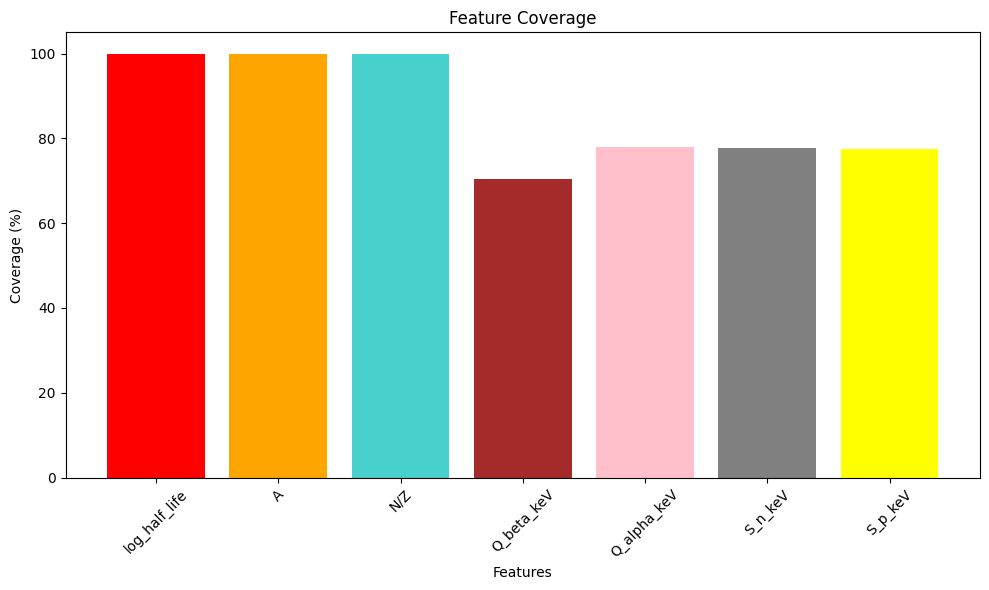

In [25]:
# Check feature coverage for ##eda_df.head() which constains all 2,796 finite half-life nuclides, including those with missing values in the candidate features.

features = [
    "log_half_life",
    "A",
    "N/Z",
    "Q_beta_keV",
    "Q_alpha_keV",
    "S_n_keV",
    "S_p_keV"
]

print("Feature coverage")
print("-" * 45)

for feature in features:
    available = sum(
        eda_df[feature].notnull() & (eda_df[feature] != "")
    )

    total = len(eda_df)
    percentage = 100 * available / total if total else 0

    print(
        f"{feature:25s} "
        f"{available:6d}/{total:<6d} "
        f"({percentage:.1f}%)"
    )

# Create a bar chart to visualize the coverage of each feature
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
for feature in features:
    available = sum(
        eda_df[feature].notnull() & (eda_df[feature] != "")
    )

    total = len(eda_df)
    percentage = 100 * available / total if total else 0

    plt.bar(feature, percentage)

plt.xlabel("Features")
plt.ylabel("Coverage (%)")
plt.title("Feature Coverage")
plt.xticks(rotation=45)
plt.tight_layout()
#change bar colours to be red, orange, blue, brown, pink, grey, yellow for each feature respectively
colors = ['red', 'orange', 'mediumturquoise', 'brown', 'pink', 'grey', 'yellow']
for i, feature in enumerate(features):
    available = sum(
        eda_df[feature].notnull() & (eda_df[feature] != "")
    )

    total = len(eda_df)
    percentage = 100 * available / total if total else 0

    plt.bar(feature, percentage, color=colors[i])


plt.show()

In [26]:
#feature coverage for eda_df.head() which constains all 2,796 finite half-life nuclides, including those with missing values in the candidate features.

features = [
    "A",
    "N/Z",
    "Q_beta_keV",
    "Q_alpha_keV",
    "S_n_keV",
    "S_p_keV"
]

missing_summary = pd.DataFrame({
    "Missing Count": eda_df[features].isna().sum(),
    "Missing (%)": eda_df[features].isna().mean() * 100,
    "Available (%)": eda_df[features].notna().mean() * 100
}).round(2)

print(missing_summary)


             Missing Count  Missing (%)  Available (%)
A                        0         0.00         100.00
N/Z                      0         0.00         100.00
Q_beta_keV             826        29.54          70.46
Q_alpha_keV            615        22.00          78.00
S_n_keV                624        22.32          77.68
S_p_keV                630        22.53          77.47


        log_half_life        A      N/Z  Q_beta_keV  Q_alpha_keV   S_n_keV  \
count         2796.00  2796.00  2796.00     1970.00      2181.00   2172.00   
mean             1.13   142.16     1.41      278.63      -681.18   7600.94   
median           1.06   142.00     1.44      551.45      -285.00   6955.00   
mode            -6.52   165.00     1.50    -9430.00    -12430.00   4970.00   
std              3.21    68.02     0.26     7346.87      7542.21   3626.23   
min            -19.34     3.00     0.50   -24190.00    -98404.00 -10026.00   
max             12.38   294.00     3.00    28440.00     56298.00  23970.00   

         S_p_keV  
count    2166.00  
mean     6756.50  
median   5571.50  
mode     1640.00  
std      5319.11  
min    -14690.00  
max     28540.00  


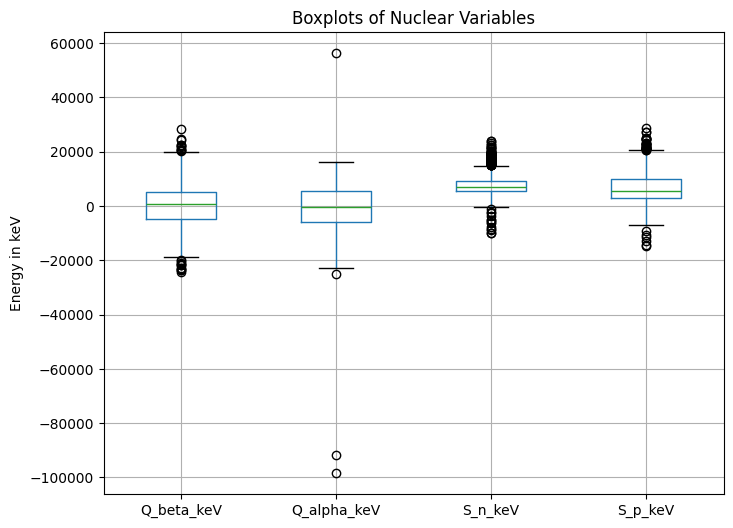

In [27]:
# Summary statistics for all features in eda_df
features = ["log_half_life", "A", "N/Z", "Q_beta_keV",
            "Q_alpha_keV", "S_n_keV", "S_p_keV"]

summary_stats = eda_df[features].agg(
    ["count", "mean", "median", lambda x: x.mode().iloc[0]
     if not x.mode().empty else float("nan"), "std", "min", "max"]
)

# Rename lambda row to "mode"
summary_stats.index = ["count", "mean", "median", "mode", "std", "min", "max"]

print(summary_stats.round(2))
summary_stats.round(2).to_clipboard(excel=True)


# Create a boxplot for each of the Q and S values to visualize their distributions  
plt.figure(figsize=(8, 6))
eda_df.boxplot(column=["Q_beta_keV", "Q_alpha_keV", "S_n_keV", "S_p_keV"])
plt.title("Boxplots of Nuclear Variables")
plt.ylabel("Energy in keV")
plt.show()

Spearman Correlation Matrix:                log_half_life  Q_beta_keV  Q_alpha_keV  S_n_keV  S_p_keV
log_half_life           1.00       -0.25         0.05     0.14     0.09
Q_beta_keV             -0.25        1.00        -0.55    -0.84     0.85
Q_alpha_keV             0.05       -0.55         1.00     0.16    -0.66
S_n_keV                 0.14       -0.84         0.16     1.00    -0.65
S_p_keV                 0.09        0.85        -0.66    -0.65     1.00


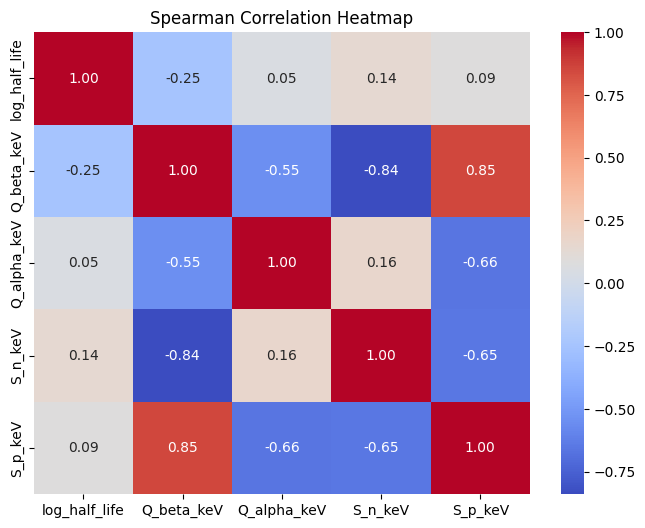

In [28]:
#Spearman correlations for the 4 energy features and the target variable log_half_life
correlation_matrix = eda_df[["log_half_life", "Q_beta_keV", "Q_alpha_keV", "S_n_keV", "S_p_keV"]].corr(method='spearman')
print("Spearman Correlation Matrix:", correlation_matrix.round(2))

#generate a heatmap to visualize the Spearman correlation matrix
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Spearman Correlation Heatmap")
plt.show()

<Figure size 1200x800 with 0 Axes>

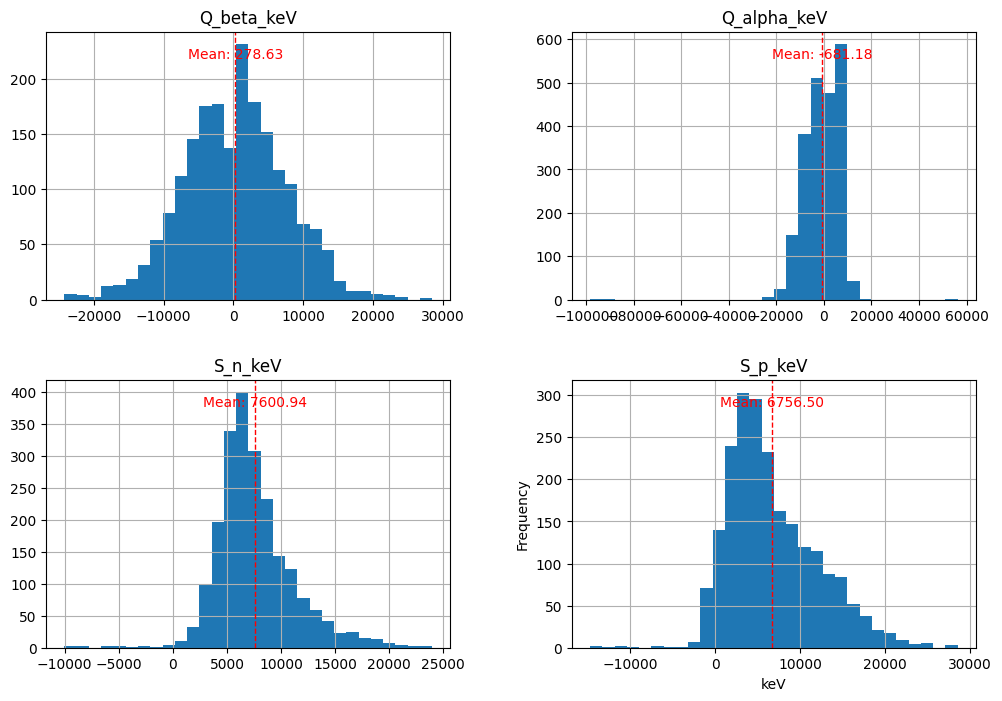

In [29]:
#generate histrograms for A, N/Z, log_half_life, Q_beta_keV, Q_alpha_keV, S_n_keV, and S_p_keV, and show their means
plt.figure(figsize=(12, 8))
eda_df[["Q_beta_keV", "Q_alpha_keV", "S_n_keV", "S_p_keV"]].hist(bins=30, figsize=(12, 8))
#display means of each feature
for i, feature in enumerate(["Q_beta_keV", "Q_alpha_keV", "S_n_keV", "S_p_keV"]):
    mean_value = eda_df[feature].mean()
    plt.subplot(2, 2, i + 1)
    plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1)
    plt.text(mean_value, plt.ylim()[1] * 0.9, f'Mean: {mean_value:.2f}', color='red', ha='center')
plt.xlabel("keV")
plt.ylabel("Frequency")
plt.show()


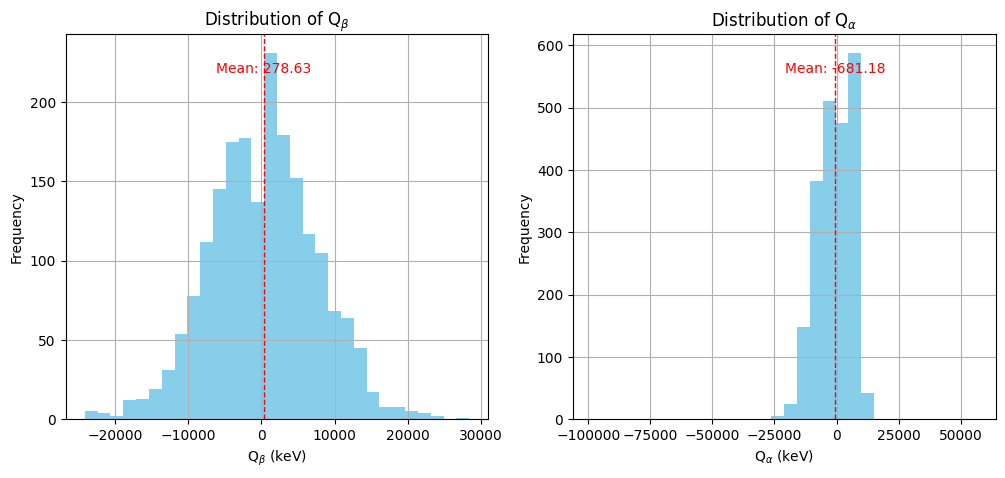

In [42]:
#generate two histograms for Q_beta_keV and Q_alpha_keV and indicate their means with a red line and label. I want the histograms to be sky blue, subscript the alpha and beta, and ensure the scales do not overlap
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
eda_df["Q_beta_keV"].hist(bins=30, color='skyblue')
mean_value = eda_df["Q_beta_keV"].mean()
plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1)
plt.text(mean_value, plt.ylim()[1] * 0.9, f'Mean: {mean_value:.2f}', color='red', ha='center')
plt.xlabel("Q$_\u03B2$ (keV)") #turn the beta into a subscript
plt.ylabel("Frequency")
plt.title("Distribution of Q$_\u03B2$")



plt.subplot(1, 2, 2)
eda_df["Q_alpha_keV"].hist(bins=30, color='skyblue')
mean_value = eda_df["Q_alpha_keV"].mean()
plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1)
plt.text(mean_value, plt.ylim()[1] * 0.9, f'Mean: {mean_value:.2f}', color='red', ha='center')
plt.xlabel("Q$_\u03B1$ (keV)") 
plt.ylabel("Frequency")
plt.title("Distribution of Q$_\u03B1$")


from matplotlib.ticker import MaxNLocator

plt.gca().xaxis.set_major_locator(MaxNLocator(nbins=8))